In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

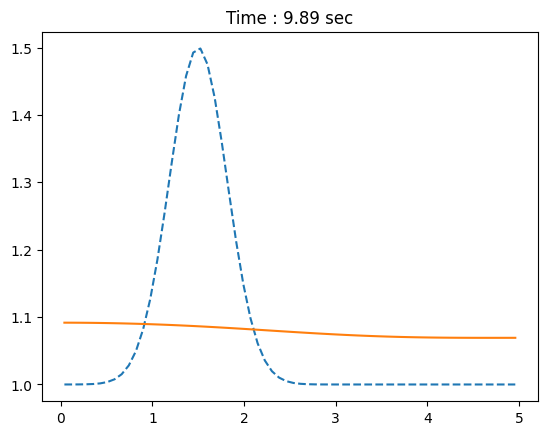

In [23]:
g = 9.8
Nx, L = 64, 5.0
dx = L / Nx
x = (np.arange(Nx) + 0.5) * dx

def F(h, hu):
    u = hu / h
    return np.array([hu, hu * u + 0.5 * g * h ** 2])

def rusanov(hL, uL, hR, uR):
    huL, huR = hL * uL, hR * uR
    FL, FR = F(hL, huL), F(hR, huR)

    vL, vR = np.abs(uL) + np.sqrt(g * hL), np.abs(uR) + np.sqrt(g * hR)
    a = np.maximum(vL, vR)
    
    qL, qR = np.array([hL, huL]), np.array([hR, huR])
    flux = 0.5 * (FL + FR) - 0.5 * a * (qR - qL)
    return flux

def L(q):
    q_ext = np.zeros((2, Nx+2))
    q_ext[:, 1:-1] = q
    q_ext[:, 0] = [q[0,0], -q[1,0]]
    q_ext[:, -1] = [q[0,-1], -q[1,-1]]
    h, u = q_ext[0], q_ext[1] / q_ext[0]
    flux = rusanov(h[:-1], u[:-1], h[1:], u[1:])
    return - (flux[:,1:] - flux[:, :-1]) / dx
    
def step_ssp_rrk3(q, dt):
    q1 = q + dt * L(q)
    q2 = 0.75 * q + 0.25 * (q1 + dt * L(q1))
    q_next = q / 3 + ( 2 / 3 ) * (q2 + dt * L(q2))
    return q_next

h0 = 1.0 + 0.5*np.exp(-5.0*(x - 1.5)**2)
q = np.array([h0, np.zeros_like(h0)])
m0 = q[0].sum() * dx

T = 10.0
t = 0.0
cfl = 0.4
k = 0
while t < T:
    h, u = q[0], q[1] / q[0]
    dt = min(cfl * dx / np.max(np.abs(u) + np.sqrt(g * h)), T - t)
    q = step_ssp_rrk3(q, dt)
    t += dt
    k += 1

    if k % 25 == 0:
        clear_output(wait=True)
        plt.plot(x,h0, '--')
        plt.plot(x,h)
        plt.title(f"Time : {t:.2f} sec")
        plt.pause(0.01)